In [1]:
import IJulia
import Base64

# The julia kernel has built in support for Revise.jl, so this is the 
# recommended approach for long-running sessions:
# https://github.com/JuliaLang/IJulia.jl/blob/9b10fa9b879574bbf720f5285029e07758e50a5e/src/kernel.jl#L46-L51

# Users should enable revise within .julia/config/startup_ijulia.jl:
# https://timholy.github.io/Revise.jl/stable/config/#Using-Revise-automatically-within-Jupyter/IJulia-1

# clear console history
IJulia.clear_history()

fig_width = 10
fig_height = 5
fig_format = :retina
fig_dpi = 96

# no retina format type, use svg for high quality type/marks
if fig_format == :retina
  fig_format = :svg
elseif fig_format == :pdf
  fig_dpi = 96
  # Enable PDF support for IJulia
  IJulia.register_mime(MIME("application/pdf"))
end

# convert inches to pixels
fig_width = fig_width * fig_dpi
fig_height = fig_height * fig_dpi

# Intialize Plots w/ default fig width/height
try
  import Plots

  # Plots.jl doesn't support PDF output for versions < 1.28.1
  # so use png (if the DPI remains the default of 300 then set to 96)
  if (Plots._current_plots_version < v"1.28.1") & (fig_format == :pdf)
    Plots.gr(size=(fig_width, fig_height), fmt = :png, dpi = fig_dpi)
  else
    Plots.gr(size=(fig_width, fig_height), fmt = fig_format, dpi = fig_dpi)
  end
catch e
  # @warn "Plots init" exception=(e, catch_backtrace())
end

# Initialize CairoMakie with default fig width/height
try
  import CairoMakie

  # CairoMakie's display() in PDF format opens an interactive window
  # instead of saving to the ipynb file, so we don't do that.
  # https://github.com/quarto-dev/quarto-cli/issues/7548
  if fig_format == :pdf
    CairoMakie.activate!(type = "png")
  else
    CairoMakie.activate!(type = string(fig_format))
  end
  CairoMakie.update_theme!(resolution=(fig_width, fig_height))
catch e
    # @warn "CairoMakie init" exception=(e, catch_backtrace())
end
  
# Set run_path if specified
try
  run_path = "L1VzZXJzL211bGxpbnNqL0Ryb3Bib3gvVGVhY2hpbmcvRUNPTjQ1MzgvbGVjdHVyZXM="
  if !isempty(run_path)
    run_path = String(Base64.base64decode(run_path))
    cd(run_path)
  end
catch e
  @warn "Run path init:" exception=(e, catch_backtrace())
end


# emulate old Pkg.installed beahvior, see
# https://discourse.julialang.org/t/how-to-use-pkg-dependencies-instead-of-pkg-installed/36416/9
import Pkg
function isinstalled(pkg::String)
  any(x -> x.name == pkg && x.is_direct_dep, values(Pkg.dependencies()))
end

# ojs_define
if isinstalled("JSON") && isinstalled("DataFrames")
  import JSON, DataFrames
  global function ojs_define(; kwargs...)
    convert(x) = x
    convert(x::DataFrames.AbstractDataFrame) = Tables.rows(x)
    content = Dict("contents" => [Dict("name" => k, "value" => convert(v)) for (k, v) in kwargs])
    tag = "<script type='ojs-define'>$(JSON.json(content))</script>"
    IJulia.display(MIME("text/html"), tag)
  end
elseif isinstalled("JSON")
  import JSON
  global function ojs_define(; kwargs...)
    content = Dict("contents" => [Dict("name" => k, "value" => v) for (k, v) in kwargs])
    tag = "<script type='ojs-define'>$(JSON.json(content))</script>"
    IJulia.display(MIME("text/html"), tag)
  end
else
  global function ojs_define(; kwargs...)
    @warn "JSON package not available. Please install the JSON.jl package to use ojs_define."
  end
end


# don't return kernel dependencies (b/c Revise should take care of dependencies)
nothing


In [2]:
#| echo: true
#| code-fold: true
#| code-line-numbers: "5-7|8-12|21-23"
#| output: asis
using Random, Statistics, LinearAlgebra, StatsPlots

function simulate(N; a = 0.8, b = 0.3, σ_e = 1.0, λ = 0.8, seed = 1234)
    rng = MersenneTwister(seed)
    lθ1 = randn(rng, N)                                  # latent log skill
    lI  = 0.5 .* lθ1 .+ randn(rng, N)                     # endogenous-looking investment
    lθ2 = a .* lθ1 .+ b .* lI .+ 0.5 .* randn(rng, N)     # technology
    M1 = lθ1 .+ σ_e .* randn(rng, N)                      # test 1 (loading = 1)
    M2 = λ .* lθ1 .+ σ_e .* randn(rng, N)                 # test 2 (different scale)
    J1 = lI .+ σ_e .* randn(rng, N)                       # investment proxy 1
    J2 = 1.5 .* lI .+ σ_e .* randn(rng, N)                # investment proxy 2
    Y  = lθ2 .+ σ_e .* randn(rng, N)                      # noisy outcome test
    return (; lθ1, lI, lθ2, M1, M2, J1, J2, Y)
end

ols(y, X) = X \ y
iv(y, X, Z) = (Z' * X) \ (Z' * y)                        # just-identified IV

d = simulate(50_000)
c = ones(length(d.Y))
b_latent = ols(d.lθ2, [c d.lθ1 d.lI])
b_ols    = ols(d.Y, [c d.M1 d.J1])
b_iv     = iv(d.Y, [c d.M1 d.J1], [c d.M2 d.J2])
est = round.([b_latent[2:3] b_ols[2:3] b_iv[2:3]], digits = 3)
println("| | Latent | Naive OLS | IV |\n|---|---|---|---|")
for (k, name) in enumerate(["Persistence \$a\$", "Investment \$b\$"])
    println("| ", name, " | ", join(est[k, :], " | "), " |")
end

| | Latent | Naive OLS | IV |
|---|---|---|---|


| Persistence $a$ | 0.797 | 0.418 | 0.806 |
| Investment $b$ | 0.305 | 0.259 | 0.31 |


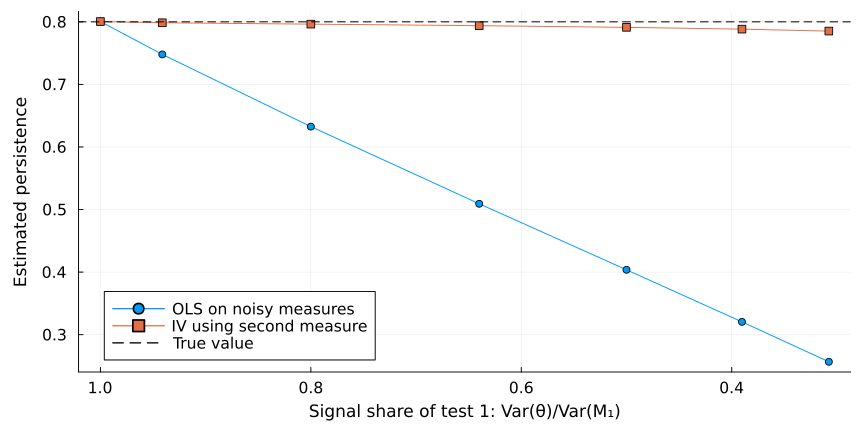

In [3]:
#| echo: true
#| code-fold: true
σs = 0.0:0.25:1.5
res = map(σs) do s
    d = simulate(50_000; σ_e = s, seed = 99)
    c = ones(length(d.Y))
    (ols(d.Y, [c d.M1 d.J1])[2], iv(d.Y, [c d.M1 d.J1], [c d.M2 d.J2])[2])
end
sig_share = 1 ./ (1 .+ collect(σs) .^ 2)   # Var(θ)/Var(M1)
plot(sig_share, first.(res), marker = :circle, label = "OLS on noisy measures",
     xlabel = "Signal share of test 1: Var(θ)/Var(M₁)", ylabel = "Estimated persistence",
     legend = :bottomleft, xflip = true, size = (900, 450),
     tickfontsize = 11, guidefontsize = 12, legendfontsize = 11,
     left_margin = 6Plots.mm, bottom_margin = 6Plots.mm)
plot!(sig_share, last.(res), marker = :square, label = "IV using second measure")
hline!([0.8], linestyle = :dash, color = :black, label = "True value")

In [4]:
#| echo: true
#| code-fold: true
#| output: asis
function ces_sim(N; γ = 0.4, φ = -0.5, σ_e = 0.7, seed = 7)
    rng = MersenneTwister(seed)
    lθ1 = randn(rng, N); lI = 0.5 .* lθ1 .+ randn(rng, N)
    lθ2 = (1/φ) .* log.(γ .* exp.(φ .* lI) .+ (1-γ) .* exp.(φ .* lθ1)) .+ 0.3 .* randn(rng, N)
    M1 = lθ1 .+ σ_e .* randn(rng, N); J1 = lI .+ σ_e .* randn(rng, N)
    return (; lθ1, lI, lθ2, M1, J1)
end
ces_pred(lθ, lI, γ, φ) = (1/φ) .* log.(γ .* exp.(φ .* lI) .+ (1-γ) .* exp.(φ .* lθ))
function fit_ces(y, lθ, lI)    # grid search for nonlinear least squares
    best = (Inf, 0.0, 0.0)
    for γ in 0.05:0.01:0.95, φ in -2.0:0.02:0.98
        abs(φ) < 1e-6 && continue
        ssr = sum(abs2, y .- ces_pred(lθ, lI, γ, φ))
        ssr < best[1] && (best = (ssr, γ, φ))
    end
    return (γ = best[2], φ = best[3], σ = round(1 / (1 - best[3]), digits = 2))
end
dc = ces_sim(5_000)
fits = (latent = fit_ces(dc.lθ2, dc.lθ1, dc.lI), noisy = fit_ces(dc.lθ2, dc.M1, dc.J1))
println("| Inputs | \$\\gamma\$ | \$\\phi\$ | \$\\sigma\$ |\n|---|---|---|---|")
for (name, r) in pairs(fits)
    println("| ", name, " | ", r.γ, " | ", r.φ, " | ", r.σ, " |")
end

| Inputs | $\gamma$ | $\phi$ | $\sigma$ |
|---|---|---|---|


| latent | 0.4 | -0.52 | 0.66 |
| noisy | 0.46 | -0.18 | 0.85 |
